# Homework 3 — Income Prediction with Logistic Regression and Random Forest

**Course:** Data Science — DS07 Supervised Learning: Classification
**Dataset:** `adult.csv` (UCI Adult / Census Income)
**Goal:** Build classification models that predict whether a person's annual income **exceeds 50K USD**.

---

### Assignment tasks

| # | Task | Section |
|---|------|---------|
| ① | Explore and browse the dataset (Exploratory Data Analysis) | [Step 1](#step1) |
| ② | Encode the `income` target: `<=50K` → **0**, `>50K` → **1** | [Step 2](#step2) |
| ③ | Split the data into a training set and a test set (test set = **20%**) | [Step 3](#step3) |
| ④ | Build Logistic Regression models with **L1** and **L2** regularization and fit them on the training set | [Step 4](#step4) |
| ⑤ | Build a **Random Forest** model and fit it on the training set | [Step 5](#step5) |
| ⑥ | Evaluate the models on the test set with **confusion matrices** and **classification reports** | [Step 6](#step6) |

### Methodology principles followed in this notebook

1. **No data leakage** — every transformation that learns from data (scaling, encoding, imputation, hyper-parameter search, threshold choice) is fitted on the **training set only**, inside a scikit-learn `Pipeline`. The test set is touched exactly once, in Step 6.
2. **Reproducibility** — a fixed `RANDOM_STATE` is used for every random operation.
3. **Fair model selection** — hyper-parameters are tuned with **stratified k-fold cross-validation** on the training set.
4. **Appropriate metrics** — the classes are imbalanced (≈ 24% earn `>50K`), so besides accuracy we report precision, recall, F1-score and ROC-AUC.

## 0. Environment setup

We import all libraries once at the top, fix the random seed, and define a consistent plotting style. The notebook was written for **Google Colab (Python 3.13)** and also runs in a local Jupyter environment.

In [1]:
import io
import inspect
import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             accuracy_score, average_precision_score, classification_report,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder, OrdinalEncoder,
                                   StandardScaler)

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "income"
CLASS_NAMES = ["<=50K", ">50K"]
PALETTE = {"<=50K": "#4C72B0", ">50K": "#DD8452"}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 50)

print(f"Python       : {platform.python_version()}")
print(f"pandas       : {pd.__version__}")
print(f"numpy        : {np.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"seaborn      : {sns.__version__}")

Python       : 3.13.18
pandas       : 3.0.5
numpy        : 2.5.3
scikit-learn : 1.9.1
seaborn      : 0.13.2


## Load the dataset

Run the cell below and **click "Choose Files"** to select `adult.csv` from your computer — no path or URL is needed.

Two loading options matter for this dataset:
* `na_values="?"` — the Adult dataset encodes unknown values as `?`; we convert them to proper missing values (`NaN`).
* `skipinitialspace=True` — some versions of the file have a space after each comma (e.g. `" Private"`); this removes it.

In [2]:
try:
    from google.colab import files  # available only inside Google Colab

    print("Please select the 'adult.csv' file ...")
    uploaded = files.upload()
    file_name = next(iter(uploaded))
    raw_df = pd.read_csv(io.BytesIO(uploaded[file_name]), na_values="?", skipinitialspace=True)
except ImportError:
    # Outside Colab (local Jupyter): read the file from the working directory.
    file_name = "adult.csv"
    raw_df = pd.read_csv(file_name, na_values="?", skipinitialspace=True)

print(f"Loaded '{file_name}' -> {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")

Loaded 'adult.csv' -> 48,842 rows x 15 columns


**Harmonising column names.** Different releases of the Adult dataset use slightly different column names (e.g. `gender` vs `sex`, `educational-num` vs `education-num`, `salary` vs `income`). We rename them to the names used in the assignment so the rest of the notebook works with any version of the file. We also strip a possible trailing `.` from the labels (the official test file writes `>50K.`).

In [3]:
COLUMN_ALIASES = {"educational-num": "education-num", "gender": "sex", "salary": "income"}

df = raw_df.rename(columns=lambda c: c.strip().lower()).rename(columns=COLUMN_ALIASES)
df[TARGET] = df[TARGET].str.strip().str.rstrip(".")

NUMERIC_COLS = df.drop(columns=TARGET).select_dtypes(include="number").columns.tolist()
CATEGORICAL_COLS = [c for c in df.columns if c not in NUMERIC_COLS + [TARGET]]

print("Numerical features  :", NUMERIC_COLS)
print("Categorical features:", CATEGORICAL_COLS)
df.head()

Numerical features  : ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


---
<a id="step1"></a>
## Step 1 — Exploratory Data Analysis (EDA)

We explore the data in a structured order:

1. Structure, data types and summary statistics
2. Data quality: missing values and duplicates
3. Target distribution (class balance)
4. Numerical features vs. income
5. Categorical features vs. income
6. Redundancy and correlation between features

### 1.1 Structure, data types and summary statistics

In [4]:
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}\n")
df.info()

Rows: 48,842 | Columns: 15

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       46043 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      46033 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  47985 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


In [5]:
df.describe().T.style.format("{:,.2f}")

,count,mean,std,min,25%,50%,75%,max
age,"48,842.00",38.64,13.71,17.00,28.00,37.00,48.00,90.00
fnlwgt,"48,842.00","189,664.13","105,604.03","12,285.00","117,550.50","178,144.50","237,642.00","1,490,400.00"
education-num,"48,842.00",10.08,2.57,1.00,9.00,10.00,12.00,16.00
capital-gain,"48,842.00","1,079.07","7,452.02",0.00,0.00,0.00,0.00,"99,999.00"
capital-loss,"48,842.00",87.50,403.00,0.00,0.00,0.00,0.00,"4,356.00"
hours-per-week,"48,842.00",40.42,12.39,1.00,40.00,40.00,45.00,99.00


In [6]:
df[CATEGORICAL_COLS + [TARGET]].describe().T

,count,unique,top,freq
workclass,46043,8,Private,33906
education,48842,16,HS-grad,15784
marital-status,48842,7,Married-civ-spouse,22379
occupation,46033,14,Prof-specialty,6172
relationship,48842,6,Husband,19716
race,48842,5,White,41762
sex,48842,2,Male,32650
native-country,47985,41,United-States,43832
income,48842,2,<=50K,37155


**Observations**
* The file contains **48,842 records and 15 columns** (6 numerical, 8 categorical, 1 target). The assignment slide mentions 32,561 records — that is the size of the original *training* part of the UCI Adult data; the provided file is the full version (training + test parts combined), which simply gives us more data to learn from. The columns are exactly the 15 described in the assignment.
* `capital-gain` and `capital-loss` are extremely skewed: the median is **0**, but the maximum is 99,999 and 4,356 respectively — most people have no capital income at all.
* `age` ranges from 17 to 90 and `hours-per-week` from 1 to 99 (median 40 = full-time work).
* `fnlwgt` is a census *sampling weight* (how many people a record represents), not a personal attribute, so we expect it to carry little predictive information.
* `native-country` has 41 distinct values but is dominated by `United-States`.

### 1.2 Data quality: missing values and duplicates

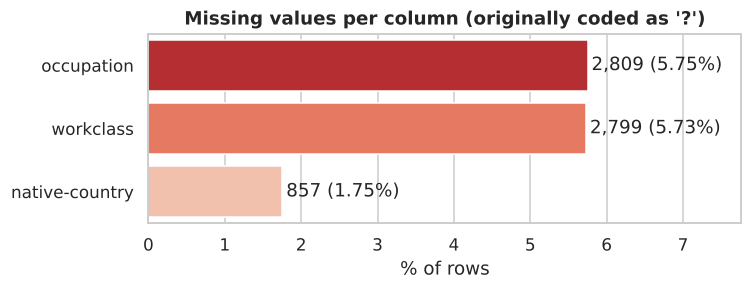

Rows with at least one missing value: 3,620 (7.41%)
Fully duplicated rows             : 52


In [7]:
missing = df.isna().sum().to_frame("missing_count")
missing["missing_pct"] = 100 * missing["missing_count"] / len(df)
missing = missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False)

fig, ax = plt.subplots(figsize=(7, 2.8))
sns.barplot(x=missing["missing_pct"], y=missing.index, hue=missing.index, palette="Reds_r",
            legend=False, ax=ax)
for i, (cnt, pct) in enumerate(zip(missing["missing_count"], missing["missing_pct"])):
    ax.text(pct + 0.05, i, f"{cnt:,} ({pct:.2f}%)", va="center")
ax.set(title="Missing values per column (originally coded as '?')", xlabel="% of rows",
       ylabel="", xlim=(0, missing["missing_pct"].max() * 1.35))
plt.tight_layout()
plt.show()

rows_with_missing = df.isna().any(axis=1).sum()
print(f"Rows with at least one missing value: {rows_with_missing:,} "
      f"({100 * rows_with_missing / len(df):.2f}%)")
print(f"Fully duplicated rows             : {df.duplicated().sum():,}")

In [8]:
# Is "missing" itself informative? Compare the share of >50K earners.
for col in missing.index:
    rate_missing = (df.loc[df[col].isna(), TARGET] == ">50K").mean()
    rate_known = (df.loc[df[col].notna(), TARGET] == ">50K").mean()
    print(f"{col:15s} | >50K rate when missing: {rate_missing:6.1%} | when known: {rate_known:6.1%}")

occupation      | >50K rate when missing:   9.4% | when known:  24.8%
workclass       | >50K rate when missing:   9.5% | when known:  24.8%
native-country  | >50K rate when missing:  25.7% | when known:  23.9%


**Observations**
* Only three columns have missing values: `occupation` (≈5.8%), `workclass` (≈5.7%) and `native-country` (≈1.8%). Missing `workclass` and `occupation` almost always occur together (people who are not in the labour force).
* The missingness is **not random**: people with an unknown `workclass`/`occupation` earn `>50K` far less often than the rest. Deleting these rows would throw away ≈7% of the data *and* a useful signal, so we will instead **replace missing values with an explicit category `"Unknown"`** — this keeps every record and lets the model learn from the missingness pattern.
* There are **52 fully duplicated rows**. With features like `fnlwgt` (a near-unique number) exact duplicates are most likely repeated records; we remove them so that the same record cannot appear in both training and test sets.

### 1.3 Target distribution (class balance)

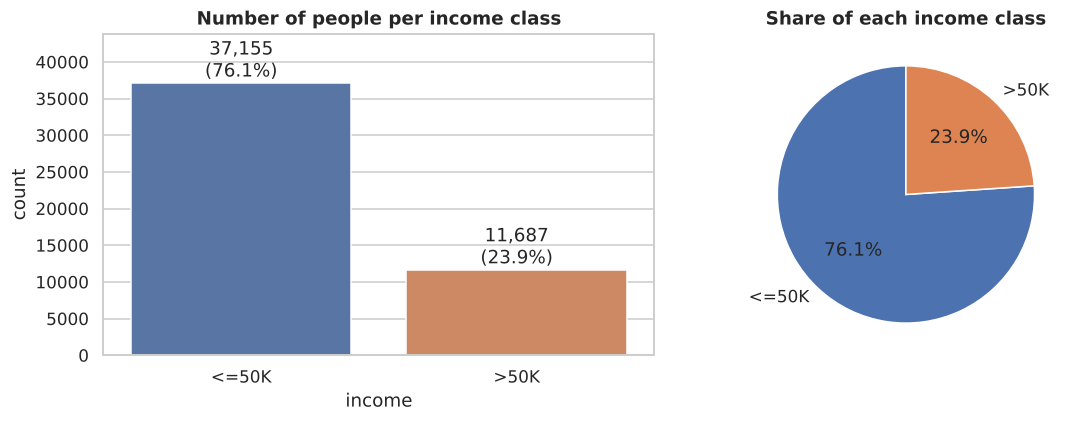

In [9]:
counts = df[TARGET].value_counts().reindex(CLASS_NAMES)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=PALETTE, legend=False,
            ax=axes[0])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom")
axes[0].set(title="Number of people per income class", xlabel="income", ylabel="count",
            ylim=(0, counts.max() * 1.18))

axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
            colors=[PALETTE[c] for c in counts.index], wedgeprops={"edgecolor": "white"})
axes[1].set_title("Share of each income class")
plt.tight_layout()
plt.show()

**Observations**
* The target is **imbalanced**: about **76%** of people earn `<=50K` and only **24%** earn `>50K` (ratio ≈ 3 : 1).
* Consequences for modelling:
  * A trivial model that always predicts `<=50K` already reaches ≈ 76% accuracy — this is the **baseline** that our models must clearly beat.
  * Accuracy alone is misleading; we will focus on **recall, precision and F1 of the `>50K` class** and on **ROC-AUC**.
  * The train/test split must be **stratified** so both sets keep the same 76/24 ratio.

### 1.4 Numerical features vs. income

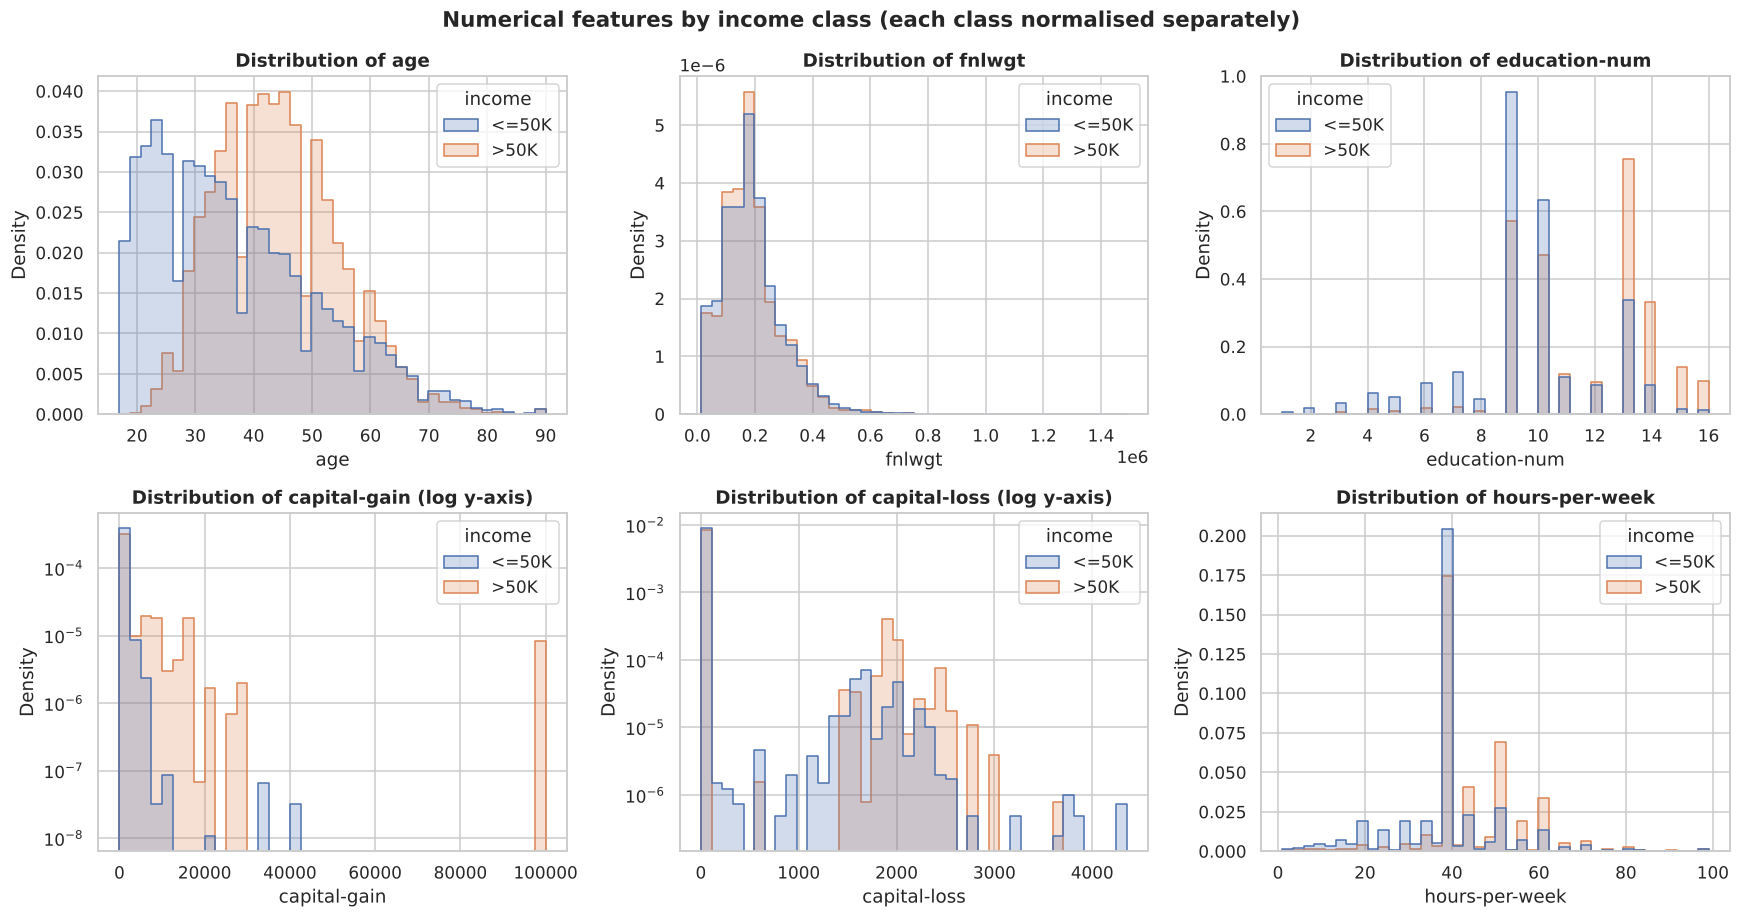

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    log_scale = col in ("capital-gain", "capital-loss")
    sns.histplot(data=df, x=col, hue=TARGET, hue_order=CLASS_NAMES, palette=PALETTE, bins=40,
                 element="step", stat="density", common_norm=False, ax=ax)
    if log_scale:
        ax.set_yscale("log")
    ax.set_title(f"Distribution of {col}" + (" (log y-axis)" if log_scale else ""))
plt.suptitle("Numerical features by income class (each class normalised separately)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

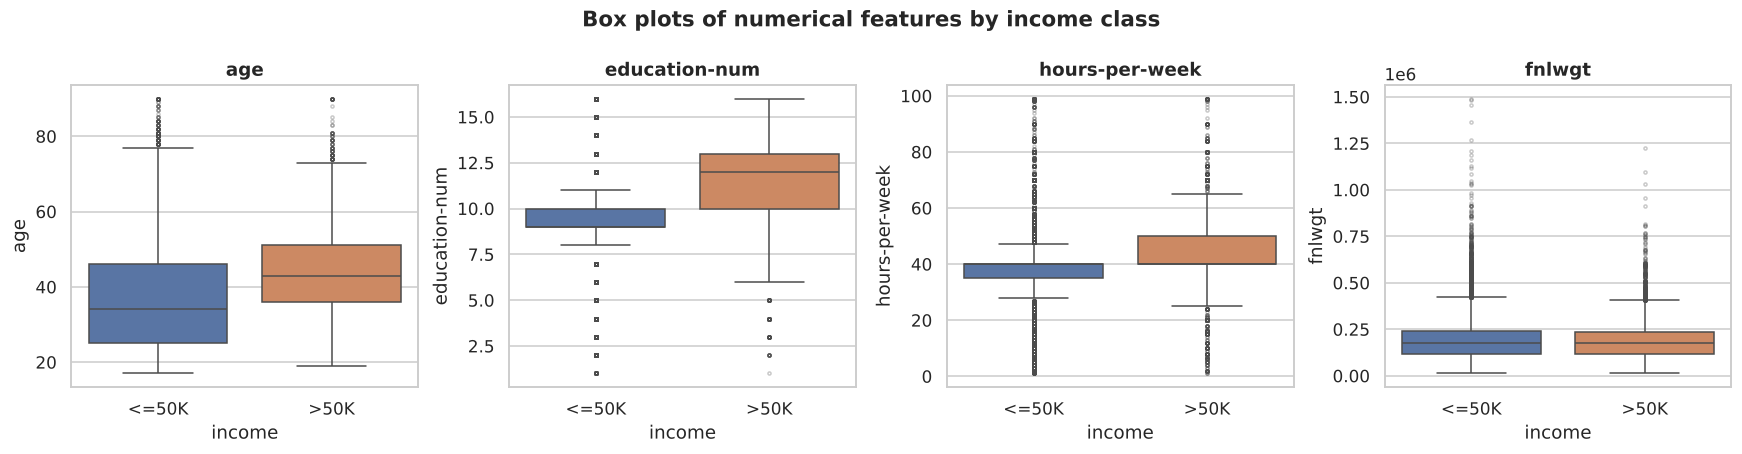

,median_<=50K,median_>50K,mean_<=50K,mean_>50K
age,34.0,43.0,36.9,44.3
fnlwgt,"178,811.0","176,729.0","190,039.6","188,470.6"
education-num,9.0,12.0,9.6,11.6
capital-gain,0.0,0.0,147.0,"4,042.2"
capital-loss,0.0,0.0,54.2,193.5
hours-per-week,40.0,40.0,38.8,45.5


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, col in zip(axes, ["age", "education-num", "hours-per-week", "fnlwgt"]):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, order=CLASS_NAMES, palette=PALETTE,
                legend=False, ax=ax, flierprops={"markersize": 2, "alpha": 0.3})
    ax.set_title(col)
plt.suptitle("Box plots of numerical features by income class", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

summary = df.groupby(TARGET)[NUMERIC_COLS].median().T
summary["mean_<=50K"] = df[df[TARGET] == "<=50K"][NUMERIC_COLS].mean()
summary["mean_>50K"] = df[df[TARGET] == ">50K"][NUMERIC_COLS].mean()
summary.columns = ["median_<=50K", "median_>50K", "mean_<=50K", "mean_>50K"]
summary.style.format("{:,.1f}")

In [12]:
has_gain = df["capital-gain"] > 0
has_loss = df["capital-loss"] > 0
print(f"People with capital-gain > 0: {has_gain.mean():.1%}")
print(f"  >50K rate | capital-gain > 0: {(df.loc[has_gain, TARGET] == '>50K').mean():.1%} "
      f"| capital-gain = 0: {(df.loc[~has_gain, TARGET] == '>50K').mean():.1%}")
print(f"People with capital-loss > 0: {has_loss.mean():.1%}")
print(f"  >50K rate | capital-loss > 0: {(df.loc[has_loss, TARGET] == '>50K').mean():.1%} "
      f"| capital-loss = 0: {(df.loc[~has_loss, TARGET] == '>50K').mean():.1%}")

People with capital-gain > 0: 8.3%
  >50K rate | capital-gain > 0: 61.7% | capital-gain = 0: 20.5%
People with capital-loss > 0: 4.7%
  >50K rate | capital-loss > 0: 50.1% | capital-loss = 0: 22.6%


**Observations**
* **`age`** — high earners are clearly older (median ≈ 43 vs ≈ 34). Income grows with career experience and peaks in middle age.
* **`education-num`** — the strongest numerical signal: the median education level of `>50K` earners is 12 (Bachelor's degree is 13) versus 9 (high-school graduate) for `<=50K`.
* **`hours-per-week`** — `>50K` earners work longer hours (mean ≈ 46 vs ≈ 39); many low earners work part-time (< 40 h).
* **`capital-gain` / `capital-loss`** — only ≈ 8% / ≈ 5% of people have any, but those who do are **much more likely to earn `>50K`**. The distributions are extremely right-skewed, so for Logistic Regression we will apply a **`log(1 + x)` transform** before scaling to reduce the effect of extreme values.
* **`fnlwgt`** — the two distributions are almost identical → confirms it has very little predictive power. We keep it (the models can ignore it) but expect a near-zero importance.
* Features have very different scales (e.g. `fnlwgt` ~ 10⁵ vs `education-num` ~ 10¹), so **standardisation is required for regularised Logistic Regression** (otherwise the L1/L2 penalty would treat features unequally).

### 1.5 Categorical features vs. income

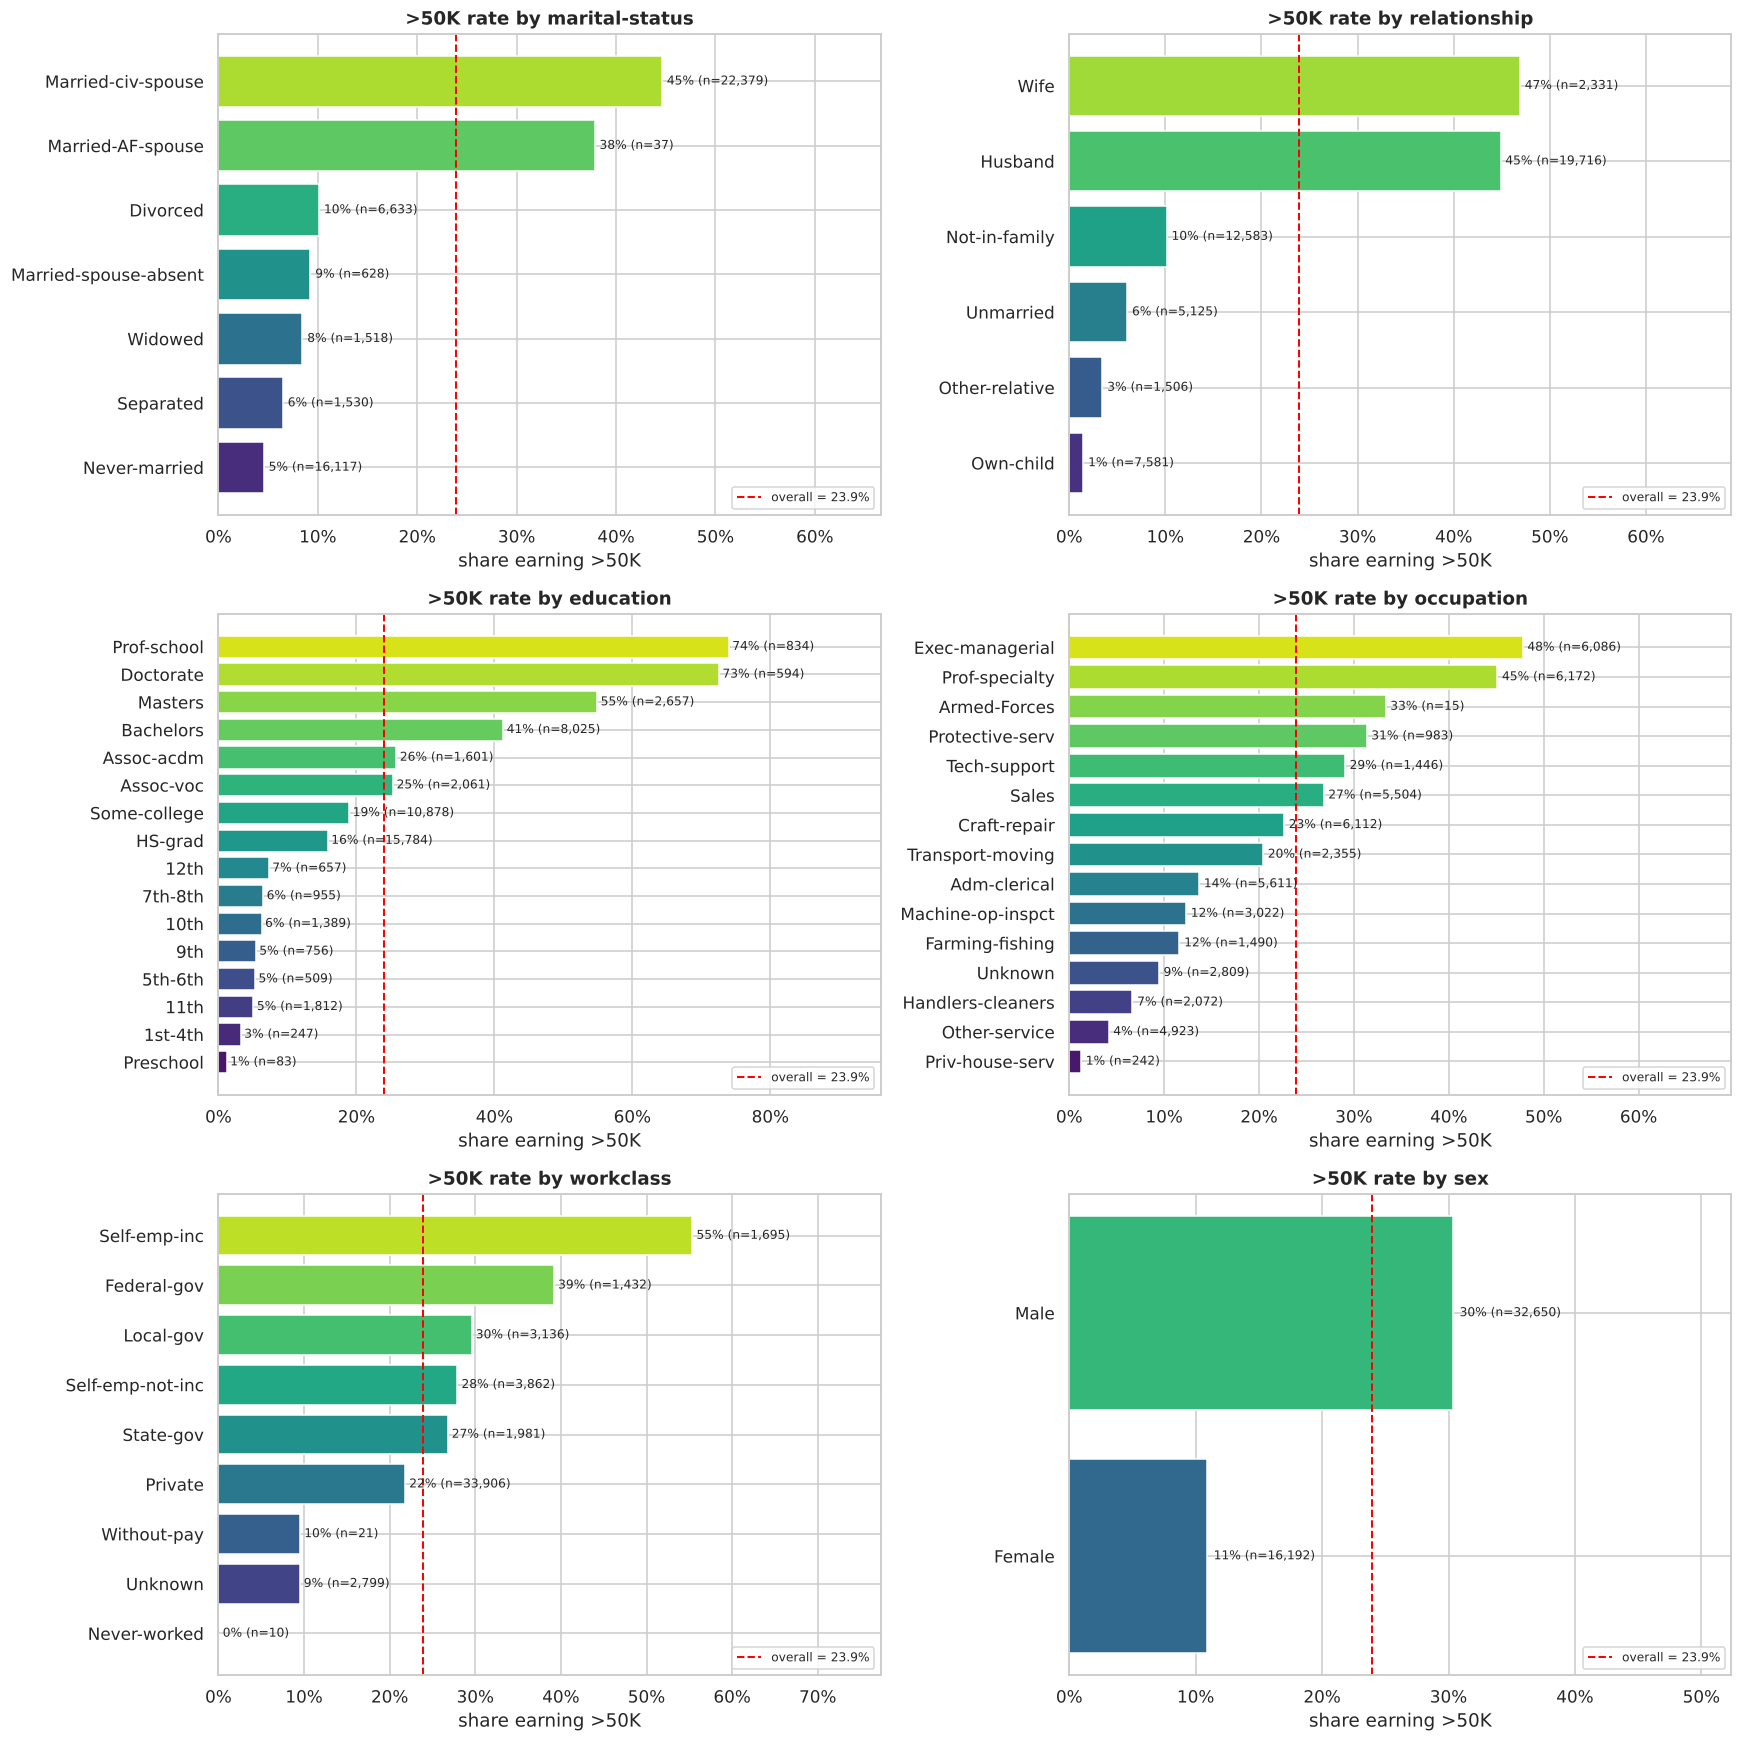

In [13]:
def plot_income_rate(ax, column, top_n=None):
    # Horizontal bar chart: share of >50K earners per category (+ category size).
    stats = (df.assign(high=df[TARGET].eq(">50K"), **{column: df[column].fillna("Unknown")})
               .groupby(column)["high"].agg(rate="mean", n="size"))
    if top_n:
        stats = stats.nlargest(top_n, "n")
    stats = stats.sort_values("rate")
    colors = sns.color_palette("viridis", len(stats))
    ax.barh(stats.index, stats["rate"], color=colors)
    ax.axvline(overall_rate, color="red", ls="--", lw=1.3, label=f"overall = {overall_rate:.1%}")
    for i, (rate, n) in enumerate(zip(stats["rate"], stats["n"])):
        ax.text(rate + 0.005, i, f"{rate:.0%} (n={n:,})", va="center", fontsize=8)
    ax.set(title=f">50K rate by {column}", xlabel="share earning >50K",
           xlim=(0, min(1, stats["rate"].max() + 0.22)))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.legend(loc="lower right", fontsize=8)


overall_rate = df[TARGET].eq(">50K").mean()
fig, axes = plt.subplots(3, 2, figsize=(16, 16))
for ax, col in zip(axes.ravel(), ["marital-status", "relationship", "education",
                                  "occupation", "workclass", "sex"]):
    plot_income_rate(ax, col)
plt.tight_layout()
plt.show()

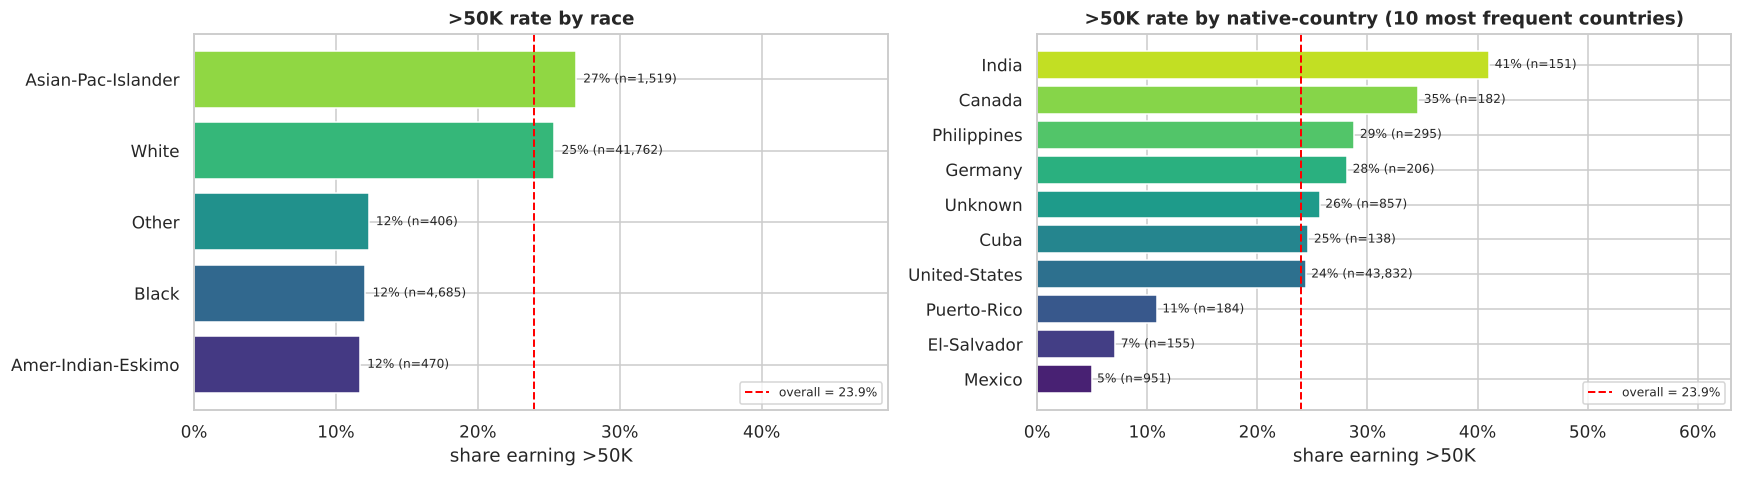

Share of records from the United States: 89.7%


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
plot_income_rate(axes[0], "race")
plot_income_rate(axes[1], "native-country", top_n=10)
axes[1].set_title(">50K rate by native-country (10 most frequent countries)")
plt.tight_layout()
plt.show()

print("Share of records from the United States:",
      f"{df['native-country'].eq('United-States').mean():.1%}")

**Observations**
* **`marital-status` & `relationship`** — the most discriminative categorical features. About **45%** of `Married-civ-spouse` people earn `>50K`, versus only **≈ 5%** of `Never-married`. Similarly, `Husband` and `Wife` have high rates while `Own-child` is close to 0% (mostly young people still living with parents). These two columns carry overlapping information (married ⇔ husband/wife).
* **`education`** — a clear monotonic pattern: `Doctorate` and `Prof-school` ≈ 73–74%, `Masters` ≈ 55%, `Bachelors` ≈ 41%, while `HS-grad` is ≈ 16% and lower levels are below 10%.
* **`occupation`** — `Exec-managerial` and `Prof-specialty` (≈ 45–48%) are far above average; `Priv-house-serv`, `Handlers-cleaners` and `Other-service` are at the bottom (< 7%). The `Unknown` group is also low, confirming the missingness signal found in 1.2.
* **`workclass`** — `Self-emp-inc` has the highest rate (≈ 55%); government jobs are above average; `Unknown`/`Never-worked`/`Without-pay` are close to zero.
* **`sex`** — males earn `>50K` about **2.7× as often** as females (≈ 30% vs ≈ 11%), reflecting the gender pay gap in the 1994 census.
* **`race` & `native-country`** — moderate differences, but ≈ 90% of records come from the US, so most countries have very few samples. One-hot encoding many rare categories adds noise; we will **group categories with fewer than 50 training samples** into an "infrequent" bucket.
* *Ethical note:* `sex`, `race` and `native-country` are sensitive attributes. They are kept here because the assignment asks for prediction accuracy, but in a real decision system their use would need a fairness review.

### 1.6 Redundancy and correlation between features

In [15]:
edu_map = df.groupby("education")["education-num"].agg(["min", "max", "nunique"]).sort_values("min")
print("Does each 'education' category map to exactly one 'education-num' value?",
      bool((edu_map["nunique"] == 1).all()))
edu_map.T

Does each 'education' category map to exactly one 'education-num' value? True


education,Preschool,1st-4th,5th-6th,7th-8th,9th,10th,11th,12th,HS-grad,Some-college,Assoc-voc,Assoc-acdm,Bachelors,Masters,Prof-school,Doctorate
min,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
max,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
nunique,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


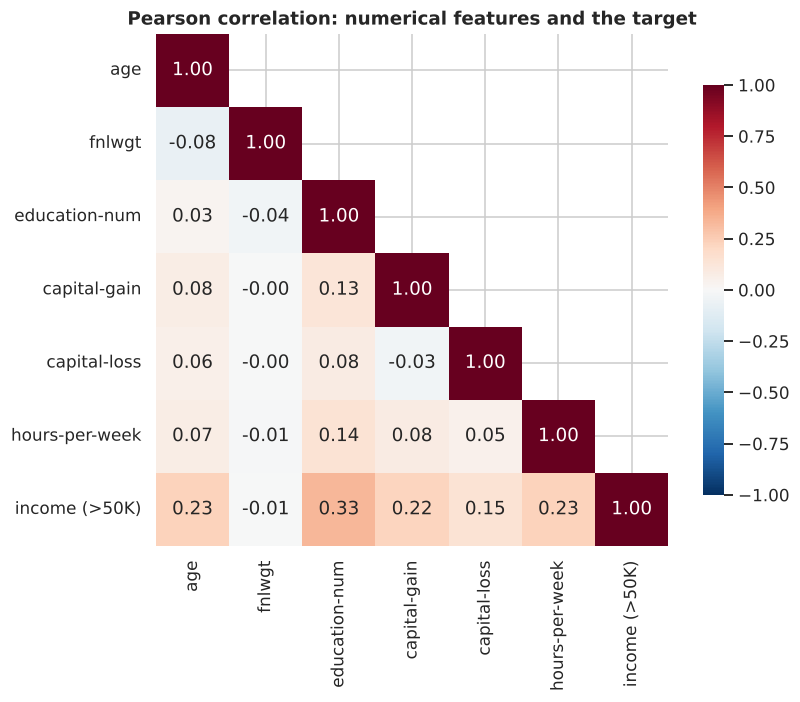

In [16]:
corr_df = df[NUMERIC_COLS].assign(**{"income (>50K)": df[TARGET].eq(">50K").astype(int)})
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), square=True,
            cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Pearson correlation: numerical features and the target")
plt.tight_layout()
plt.show()

**Observations**
* **`education` and `education-num` are perfectly redundant**: every education category corresponds to exactly one number (e.g. `Bachelors` = 13), and the number preserves the natural order of degrees. We therefore **drop `education`** and keep the ordinal `education-num` (1 column instead of 16 dummy columns, no information lost).
* Correlations among the numerical features are weak (all |r| < 0.15) → no multicollinearity problem for Logistic Regression.
* The numerical features most correlated with the target are `education-num` (0.33), `age` (0.23), `hours-per-week` (0.23) and `capital-gain` (0.22); `fnlwgt` is ≈ 0, confirming the observation in 1.4.

### EDA summary → decisions for preprocessing

| Finding | Decision |
|---|---|
| `?` = unknown values, missingness is informative | Impute with the category `"Unknown"` |
| 52 duplicated rows | Remove them |
| `education` ≡ `education-num` | Drop `education` |
| Target imbalanced (76 / 24) | Stratified split & CV; evaluate with F1 / recall / ROC-AUC |
| Heavily skewed `capital-gain/loss`, very different scales | `log1p` + standardisation (Logistic Regression) |
| Many rare categories (`native-country`, …) | One-hot encoding with an "infrequent" bucket (min. 50 samples) |

---
<a id="step2"></a>
## Step 2 — Data cleaning and target encoding

We apply the cleaning decisions taken in the EDA and convert the target into a binary variable as required: **`<=50K` → 0** and **`>50K` → 1**.

In [17]:
n_before = len(df)
clean_df = df.drop_duplicates().drop(columns="education").reset_index(drop=True)
print(f"Removed duplicated rows : {n_before - len(clean_df):,}")
print(f"Dropped column          : 'education' (redundant with 'education-num')")
print(f"Remaining data          : {clean_df.shape[0]:,} rows x {clean_df.shape[1]} columns")

# Target encoding: '<=50K' -> 0, '>50K' -> 1
INCOME_MAP = {"<=50K": 0, ">50K": 1}
assert set(clean_df[TARGET].unique()) == set(INCOME_MAP), "Unexpected income labels"
clean_df[TARGET] = clean_df[TARGET].map(INCOME_MAP).astype(int)

print("\nEncoded target distribution:")
print(pd.DataFrame({"count": clean_df[TARGET].value_counts().sort_index(),
                    "share": clean_df[TARGET].value_counts(normalize=True).sort_index().round(4)}))

Removed duplicated rows : 52
Dropped column          : 'education' (redundant with 'education-num')
Remaining data          : 48,790 rows x 14 columns

Encoded target distribution:
        count   share
income               
0       37109  0.7606
1       11681  0.2394


In [18]:
X = clean_df.drop(columns=TARGET)
y = clean_df[TARGET]

NUMERIC_FEATURES = X.select_dtypes(include="number").columns.tolist()
CATEGORICAL_FEATURES = [c for c in X.columns if c not in NUMERIC_FEATURES]
print("Numerical features  :", NUMERIC_FEATURES)
print("Categorical features:", CATEGORICAL_FEATURES)

Numerical features  : ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical features: ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


**Note:** missing values are *not* filled here. Imputation is a learned transformation, so it is placed inside the modelling pipeline (Step 4/5) and is fitted on the training data only.

---
<a id="step3"></a>
## Step 3 — Train / test split (test set = 20%)

* `test_size=0.20` → 80% of the data for training, 20% held out for the final evaluation.
* `stratify=y` → both sets keep the same proportion of `>50K` earners (important because the classes are imbalanced).
* `random_state=42` → the split is reproducible.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

split_info = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "share_of_data": [len(X_train) / len(X), len(X_test) / len(X)],
    "share_>50K": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])
split_info.style.format({"rows": "{:,}", "share_of_data": "{:.1%}", "share_>50K": "{:.2%}"})

,rows,share_of_data,share_>50K
train,"39,032",80.0%,23.94%
test,"9,758",20.0%,23.94%


**Observation:** the split is exactly 80/20 and the share of `>50K` earners is ≈ 23.9% in *both* sets, so the test set is a faithful, representative sample of the data.

---
<a id="step4"></a>
## Step 4 — Logistic Regression with L1 and L2 regularization

### 4.1 Preprocessing pipeline

Logistic Regression needs purely numerical, comparably-scaled inputs. The `ColumnTransformer` below applies:

| Columns | Transformation | Reason |
|---|---|---|
| `capital-gain`, `capital-loss` | `log1p` → `StandardScaler` | reduce extreme skew, then put on a common scale |
| other numerical columns | `StandardScaler` | mean 0 / std 1, so the penalty treats all coefficients fairly |
| categorical columns | impute `"Unknown"` → `OneHotEncoder` | one binary column per category; categories with < 50 training samples are grouped as *infrequent*; unseen categories at test time are ignored safely |

### 4.2 Regularization

Logistic Regression minimises the log-loss plus a penalty on the coefficients **w**, controlled by `C` (the *inverse* of the regularization strength — a small `C` means a strong penalty):

* **L2 (Ridge):** penalty $\frac{1}{2}\lVert\mathbf{w}\rVert_2^2$ — shrinks all coefficients smoothly towards 0; handles correlated features well.
* **L1 (Lasso):** penalty $\lVert\mathbf{w}\rVert_1$ — can set coefficients **exactly to 0**, performing automatic feature selection and giving a sparser, more interpretable model.

The best `C` for each penalty is selected by **5-fold stratified cross-validation** on the training set, using **ROC-AUC** as the selection criterion (threshold-independent and robust to class imbalance).

In [20]:
LOG_FEATURES = ["capital-gain", "capital-loss"]
SCALE_FEATURES = [c for c in NUMERIC_FEATURES if c not in LOG_FEATURES]

categorical_onehot = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50,
                             sparse_output=False)),
])

linear_preprocessor = ColumnTransformer([
    ("log_scaled", Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                             ("scale", StandardScaler())]), LOG_FEATURES),
    ("scaled", StandardScaler(), SCALE_FEATURES),
    ("categorical", categorical_onehot, CATEGORICAL_FEATURES),
], verbose_feature_names_out=False)

n_features = linear_preprocessor.fit(X_train).get_feature_names_out().size
print(f"Number of model inputs after preprocessing: {n_features}")

Number of model inputs after preprocessing: 75


**Version-compatibility helper.** Starting with scikit-learn 1.8, the `penalty` argument of `LogisticRegression` is deprecated and the penalty type is chosen with `l1_ratio` (`0` = L2, `1` = L1). The helper below detects the installed version and uses the correct argument, so the notebook runs without warnings on both older and newer versions (including the one installed on Colab).

We use the `liblinear` solver, which supports both L1 and L2 penalties and is very efficient for binary problems of this size.

In [21]:
_PENALTY_DEPRECATED = (
    inspect.signature(LogisticRegression).parameters.get("penalty") is None
    or inspect.signature(LogisticRegression).parameters["penalty"].default == "deprecated"
)


def make_logistic_regression(penalty, C=1.0):
    # Create a LogisticRegression with an 'l1' or 'l2' penalty (works on all sklearn versions).
    if penalty not in ("l1", "l2"):
        raise ValueError("penalty must be 'l1' or 'l2'")
    penalty_kwargs = ({"l1_ratio": 1.0 if penalty == "l1" else 0.0} if _PENALTY_DEPRECATED
                      else {"penalty": penalty})
    return LogisticRegression(C=C, solver="liblinear", max_iter=5000,
                              random_state=RANDOM_STATE, **penalty_kwargs)


CV_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"roc_auc": "roc_auc", "accuracy": "accuracy", "f1": "f1"}
C_GRID = np.logspace(-3, 2, 11)  # 0.001 ... 100

### 4.3 Hyper-parameter tuning (C) with 5-fold cross-validation

In [22]:
logreg_searches = {}
for penalty in ("l1", "l2"):
    pipe = Pipeline([("preprocess", linear_preprocessor),
                     ("model", make_logistic_regression(penalty))])
    search = GridSearchCV(pipe, {"model__C": C_GRID}, cv=CV_5, scoring=SCORING,
                          refit="roc_auc", n_jobs=-1)
    search.fit(X_train, y_train)
    logreg_searches[penalty] = search

    best = search.best_index_
    res = search.cv_results_
    print(f"[{penalty.upper()}] best C = {search.best_params_['model__C']:.4g} | "
          f"CV ROC-AUC = {res['mean_test_roc_auc'][best]:.4f} ± {res['std_test_roc_auc'][best]:.4f} | "
          f"CV accuracy = {res['mean_test_accuracy'][best]:.4f} | "
          f"CV F1 = {res['mean_test_f1'][best]:.4f}")

logreg_l1 = logreg_searches["l1"].best_estimator_
logreg_l2 = logreg_searches["l2"].best_estimator_

[L1] best C = 1 | CV ROC-AUC = 0.9008 ± 0.0014 | CV accuracy = 0.8468 | CV F1 = 0.6498


[L2] best C = 0.3162 | CV ROC-AUC = 0.9008 ± 0.0014 | CV accuracy = 0.8471 | CV F1 = 0.6500


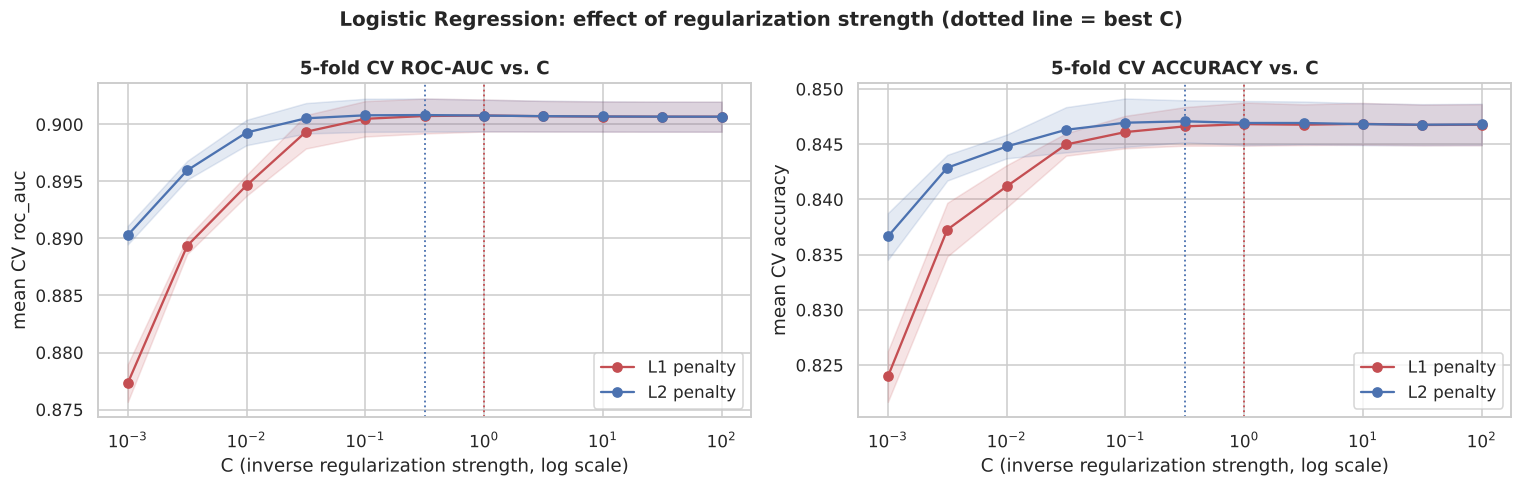

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for metric, ax in zip(["roc_auc", "accuracy"], axes):
    for penalty, color in [("l1", "#C44E52"), ("l2", "#4C72B0")]:
        res = logreg_searches[penalty].cv_results_
        mean, std = res[f"mean_test_{metric}"], res[f"std_test_{metric}"]
        ax.semilogx(C_GRID, mean, marker="o", color=color, label=f"{penalty.upper()} penalty")
        ax.fill_between(C_GRID, mean - std, mean + std, color=color, alpha=0.15)
        best_c = logreg_searches[penalty].best_params_["model__C"]
        ax.axvline(best_c, color=color, ls=":", lw=1.2)
    ax.set(title=f"5-fold CV {metric.replace('_', '-').upper()} vs. C",
           xlabel="C (inverse regularization strength, log scale)", ylabel=f"mean CV {metric}")
    ax.legend()
plt.suptitle("Logistic Regression: effect of regularization strength (dotted line = best C)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Observations**
* With very small `C` (strong regularization) both models **under-fit**: the L1 model in particular sets almost all coefficients to zero and its performance collapses.
* Performance rises quickly and reaches a **plateau from `C ≈ 0.1`** onwards; beyond this, weaker regularization brings no gain — the dataset is large (≈ 39,000 training rows) relative to the number of inputs, so over-fitting is not a major risk for a linear model.
* The best L1 and L2 models reach almost **identical cross-validated performance (ROC-AUC ≈ 0.90)**. The small standard deviation across folds shows that the results are stable.

### 4.4 Interpreting the coefficients

L1 model: 10 of 75 coefficients are exactly 0 -> 65 features kept
L2 model: 0 coefficients are exactly 0


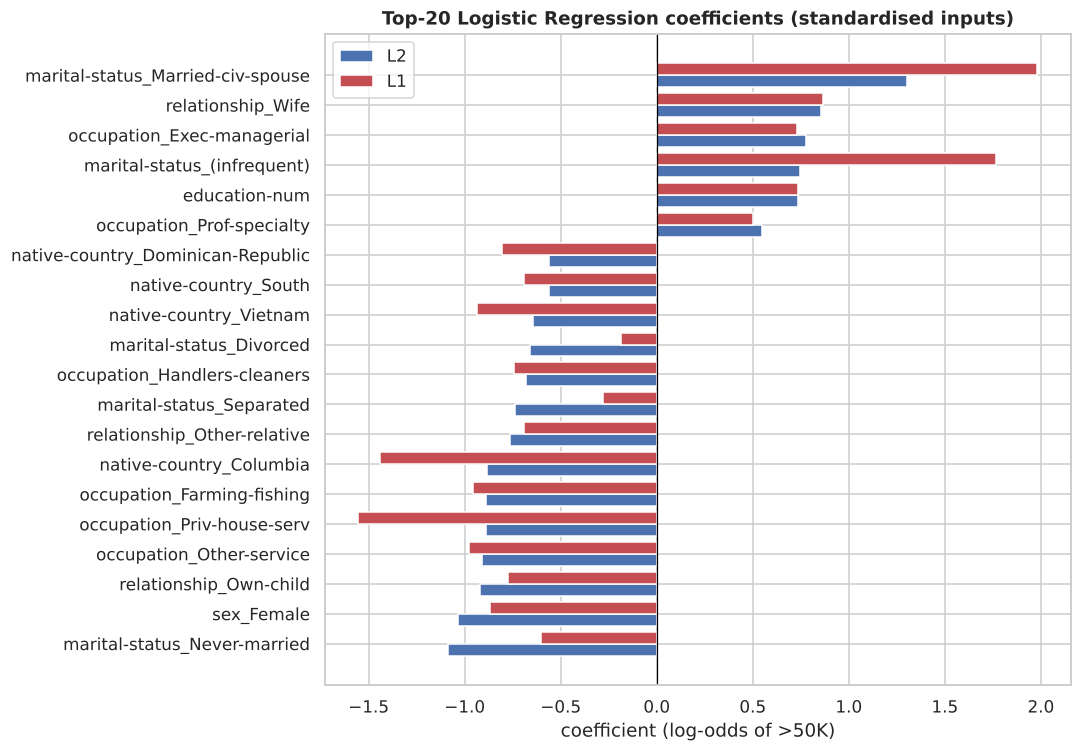

In [24]:
feature_names = [name.replace("infrequent_sklearn", "(infrequent)") for name in
                 logreg_l2.named_steps["preprocess"].get_feature_names_out()]
coefs = pd.DataFrame({
    "L1": logreg_l1.named_steps["model"].coef_.ravel(),
    "L2": logreg_l2.named_steps["model"].coef_.ravel(),
}, index=feature_names)

n_zero = int((coefs["L1"].abs() < 1e-10).sum())
print(f"L1 model: {n_zero} of {len(coefs)} coefficients are exactly 0 "
      f"-> {len(coefs) - n_zero} features kept")
print(f"L2 model: {int((coefs['L2'].abs() < 1e-10).sum())} coefficients are exactly 0")

top = coefs.loc[coefs["L2"].abs().sort_values(ascending=False).index[:20]].sort_values("L2")
fig, ax = plt.subplots(figsize=(10, 7))
y_pos = np.arange(len(top))
ax.barh(y_pos - 0.2, top["L2"], height=0.4, color="#4C72B0", label="L2")
ax.barh(y_pos + 0.2, top["L1"], height=0.4, color="#C44E52", label="L1")
ax.set_yticks(y_pos, top.index)
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Top-20 Logistic Regression coefficients (standardised inputs)",
       xlabel="coefficient (log-odds of >50K)")
ax.legend()
plt.tight_layout()
plt.show()

**Observations**
* Because numerical inputs are standardised, coefficient magnitudes are directly comparable. A **positive** coefficient increases the odds of earning `>50K`; a negative one decreases them (the coefficient of a dummy column is measured relative to the dropped/other categories).
* The strongest positive drivers are **being married (`Married-civ-spouse`, `Wife`)**, a **managerial or professional occupation** (`Exec-managerial`, `Prof-specialty`) and a higher **education level** (`education-num`). The `marital-status_(infrequent)` column groups the very rare `Married-AF-spouse` category (married to a member of the armed forces), which behaves like `Married-civ-spouse`.
* The strongest negative drivers are **`Never-married`**, **`sex_Female`**, `Own-child`, and low-paid occupations (`Other-service`, `Priv-house-serv`, `Farming-fishing`, `Handlers-cleaners`) — exactly the patterns seen in the EDA (Section 1.5).
* A few small native-country groups (e.g. `Columbia`, `Vietnam`) receive large negative coefficients; with only ~50–100 people each these estimates are uncertain and should not be over-interpreted.
* The **L1 model sets 10 of the 75 coefficients exactly to 0** (redundant or uninformative dummy columns, mostly countries and overlapping marital-status / relationship categories) while keeping the same predictive performance — a simpler, more interpretable model. L1 tends to concentrate weight on one column of a correlated group (e.g. larger `Married-civ-spouse`, smaller `Divorced`/`Separated`), whereas L2 spreads it more evenly and keeps every coefficient non-zero.

---
<a id="step5"></a>
## Step 5 — Random Forest

A Random Forest is an ensemble of decision trees, each trained on a bootstrap sample of the rows and considering a random subset of features at every split. Averaging many de-correlated trees reduces variance and captures **non-linear relationships and feature interactions** (e.g. age × education) that a linear model cannot represent.

**Preprocessing for trees:** trees are invariant to monotonic transformations, so no scaling or log transform is needed. Categorical columns are imputed with `"Unknown"` and converted with an `OrdinalEncoder` (one integer per category) — compact and efficient for tree models.

### 5.1 Baseline Random Forest (default hyper-parameters)

In [25]:
tree_preprocessor = ColumnTransformer([
    ("numeric", "passthrough", NUMERIC_FEATURES),
    ("categorical", Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
    ]), CATEGORICAL_FEATURES),
], verbose_feature_names_out=False)

rf_default = Pipeline([
    ("preprocess", tree_preprocessor),
    ("model", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)),
])
rf_default.fit(X_train, y_train)

train_acc = accuracy_score(y_train, rf_default.predict(X_train))
cv_auc_default = GridSearchCV(rf_default, {}, cv=StratifiedKFold(3, shuffle=True,
                              random_state=RANDOM_STATE), scoring="roc_auc", n_jobs=-1
                              ).fit(X_train, y_train).best_score_
print(f"Default RF -> training accuracy = {train_acc:.4f} | 3-fold CV ROC-AUC = {cv_auc_default:.4f}")

Default RF -> training accuracy = 0.9999 | 3-fold CV ROC-AUC = 0.9083


**Observation:** with default settings each tree is grown until its leaves are pure, so the forest almost **memorises the training set** (training accuracy ≈ 100%) — a sign of **over-fitting**. Limiting tree depth and leaf size should generalise better.

### 5.2 Hyper-parameter tuning with cross-validation

We tune the parameters that control tree complexity:
* `max_depth` — maximum depth of each tree;
* `min_samples_leaf` — minimum number of samples in a leaf (larger → smoother decision boundary);
* `max_features` — fraction of features considered at each split (controls tree diversity).

`n_estimators` is fixed at 300 (more trees never hurt accuracy, they only cost time). We use **3-fold** stratified CV here to keep the run time reasonable on Colab (72 forest fits — this cell takes a few minutes).

In [26]:
rf_param_grid = {
    "model__max_depth": [12, 16, 20, None],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.5],
}
CV_3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Parallelise over the CV fits (n_jobs=-1) and keep each forest single-threaded to avoid
# over-subscribing the CPU cores.
rf_search = GridSearchCV(clone(rf_default).set_params(model__n_jobs=1), rf_param_grid, cv=CV_3, scoring=SCORING, refit="roc_auc",
                         n_jobs=-1)
rf_search.fit(X_train, y_train)
random_forest = rf_search.best_estimator_.set_params(model__n_jobs=-1)

best = rf_search.best_index_
res = rf_search.cv_results_
print("Best parameters:", {k.replace("model__", ""): v for k, v in rf_search.best_params_.items()})
print(f"CV ROC-AUC = {res['mean_test_roc_auc'][best]:.4f} ± {res['std_test_roc_auc'][best]:.4f} | "
      f"CV accuracy = {res['mean_test_accuracy'][best]:.4f} | CV F1 = {res['mean_test_f1'][best]:.4f}")
print(f"Training accuracy of the tuned forest = {accuracy_score(y_train, random_forest.predict(X_train)):.4f}")

Best parameters: {'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 2}
CV ROC-AUC = 0.9187 ± 0.0006 | CV accuracy = 0.8643 | CV F1 = 0.6787


Training accuracy of the tuned forest = 0.8960


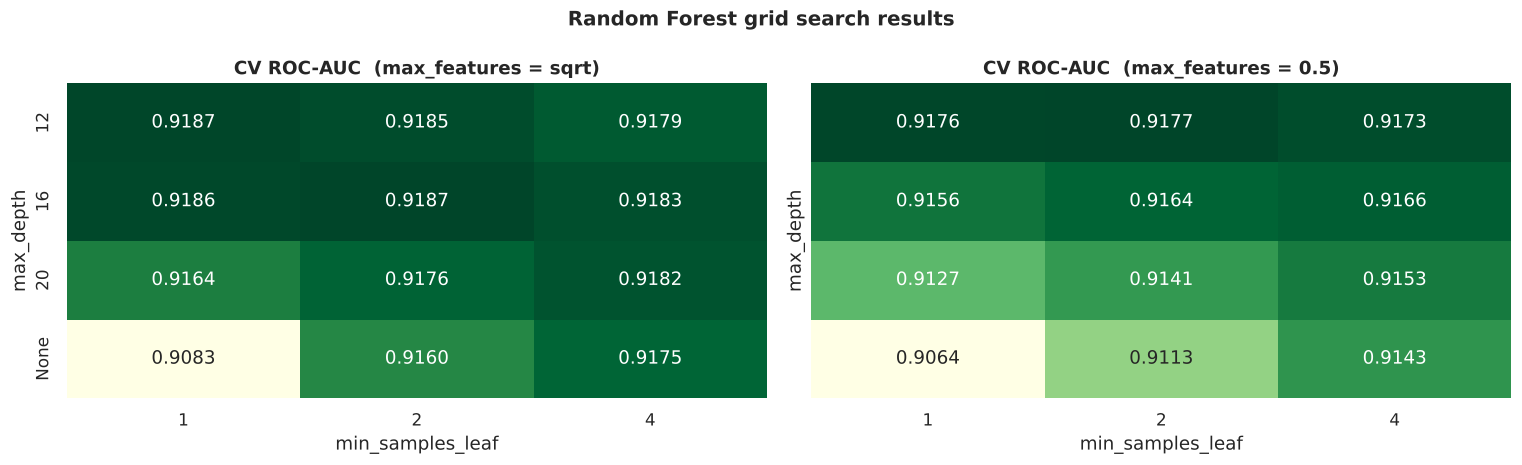

In [27]:
grid_results = pd.DataFrame(res["params"]).rename(columns=lambda c: c.replace("model__", ""))
grid_results["cv_roc_auc"] = res["mean_test_roc_auc"]
grid_results["max_depth"] = grid_results["max_depth"].map(
    lambda d: "None" if d is None or pd.isna(d) else str(int(d)))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), sharey=True)
for ax, mf in zip(axes, ["sqrt", 0.5]):
    pivot = (grid_results[grid_results["max_features"].astype(str) == str(mf)]
             .pivot(index="max_depth", columns="min_samples_leaf", values="cv_roc_auc")
             .reindex(["12", "16", "20", "None"]))
    sns.heatmap(pivot, annot=True, fmt=".4f", cmap="YlGn", ax=ax, cbar=False)
    ax.set_title(f"CV ROC-AUC  (max_features = {mf})")
plt.suptitle("Random Forest grid search results", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Observations**
* The best configuration is **`max_depth=16`, `min_samples_leaf=2`, `max_features="sqrt"`** (CV ROC-AUC ≈ 0.919), clearly better than the fully-grown default forest (`max_depth=None`, `min_samples_leaf=1`: CV ROC-AUC ≈ 0.908). The heat map shows a flat plateau for `max_depth` 12–16 (differences < 0.0005), and performance degrades towards deeper / fully-grown trees, so the search range covers the optimum well.
* Constraining the trees reduces over-fitting: the training accuracy drops from ≈ 100% to ≈ 90%, i.e. the forest stops memorising individual records and generalises better.
* `max_features="sqrt"` (≈ 3 of 13 features per split) beats `0.5`: more randomness gives more diverse, less correlated trees.
* The surface is fairly flat around the optimum: the forest is robust to small changes of its hyper-parameters, so the choice is reliable rather than a lucky fluke.

### 5.3 Feature importance (impurity-based)

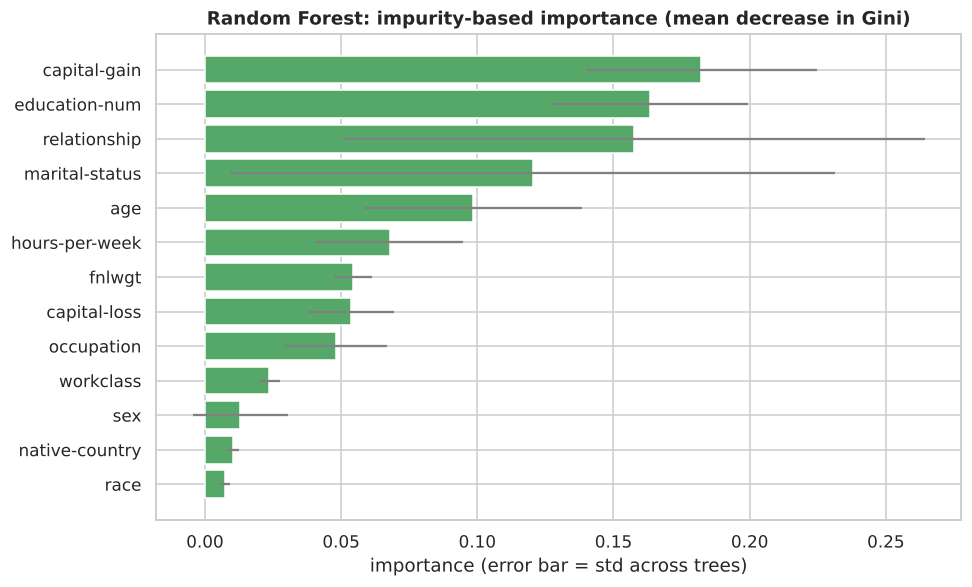

In [28]:
rf_model = random_forest.named_steps["model"]
rf_feature_names = random_forest.named_steps["preprocess"].get_feature_names_out()
impurity_imp = pd.Series(rf_model.feature_importances_, index=rf_feature_names)
impurity_std = pd.Series(np.std([t.feature_importances_ for t in rf_model.estimators_], axis=0),
                         index=rf_feature_names)

fig, ax = plt.subplots(figsize=(9, 5.5))
order = impurity_imp.sort_values().index
ax.barh(order, impurity_imp[order], xerr=impurity_std[order], color="#55A868", ecolor="gray")
ax.set(title="Random Forest: impurity-based importance (mean decrease in Gini)",
       xlabel="importance (error bar = std across trees)")
plt.tight_layout()
plt.show()

**Observations**
* According to the Gini criterion, the most important features are **`capital-gain`, `education-num`, `relationship`, `marital-status` and `age`**, followed by `hours-per-week` — consistent with the EDA and the Logistic Regression coefficients. `sex`, `native-country` and `race` contribute very little.
* The large error bars of `relationship` and `marital-status` show that individual trees use either one or the other: they contain overlapping information, so when one of them is selected at the top of a tree the other becomes less useful.
* Impurity-based importance is computed from the training data and is known to be **biased towards continuous, high-cardinality features** such as `fnlwgt`. We therefore confirm these results with *permutation importance on the test set* in Step 6.6.

---
<a id="step6"></a>
## Step 6 — Evaluation on the test set

The test set (20%, never used so far) is now used **once** to obtain an unbiased estimate of each model's performance. We compare four models:

1. **Logistic Regression (L1)** — tuned `C`
2. **Logistic Regression (L2)** — tuned `C`
3. **Random Forest (default)** — reference
4. **Random Forest (tuned)** — best grid-search parameters

### 6.1 Classification reports

In [29]:
models = {
    "Logistic Regression (L1)": logreg_l1,
    "Logistic Regression (L2)": logreg_l2,
    "Random Forest (default)": rf_default,
    "Random Forest (tuned)": random_forest,
}


def evaluate(name, model, X_eval, y_eval, threshold=0.5):
    # Return the main metrics of a fitted binary classifier at a given decision threshold.
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "model": name,
        "threshold": threshold,
        "accuracy": accuracy_score(y_eval, pred),
        "precision (>50K)": precision_score(y_eval, pred),
        "recall (>50K)": recall_score(y_eval, pred),
        "F1 (>50K)": f1_score(y_eval, pred),
        "F1 (macro)": f1_score(y_eval, pred, average="macro"),
        "ROC-AUC": roc_auc_score(y_eval, proba),
        "PR-AUC": average_precision_score(y_eval, proba),
    }


for name, model in models.items():
    print("=" * 62)
    print(f"{name}")
    print("=" * 62)
    print(classification_report(y_test, model.predict(X_test), target_names=CLASS_NAMES, digits=4))

Logistic Regression (L1)
              precision    recall  f1-score   support

       <=50K     0.8750    0.9245    0.8991      7422
        >50K     0.7077    0.5805    0.6378      2336

    accuracy                         0.8422      9758
   macro avg     0.7914    0.7525    0.7685      9758
weighted avg     0.8350    0.8422    0.8366      9758

Logistic Regression (L2)
              precision    recall  f1-score   support

       <=50K     0.8754    0.9255    0.8997      7422
        >50K     0.7106    0.5813    0.6395      2336

    accuracy                         0.8431      9758
   macro avg     0.7930    0.7534    0.7696      9758
weighted avg     0.8359    0.8431    0.8374      9758

Random Forest (default)


              precision    recall  f1-score   support

       <=50K     0.8919    0.9309    0.9110      7422
        >50K     0.7450    0.6417    0.6895      2336

    accuracy                         0.8617      9758
   macro avg     0.8185    0.7863    0.8003      9758
weighted avg     0.8568    0.8617    0.8580      9758

Random Forest (tuned)
              precision    recall  f1-score   support

       <=50K     0.8838    0.9458    0.9138      7422
        >50K     0.7785    0.6049    0.6808      2336

    accuracy                         0.8642      9758
   macro avg     0.8312    0.7754    0.7973      9758
weighted avg     0.8586    0.8642    0.8580      9758



### 6.2 Confusion matrices

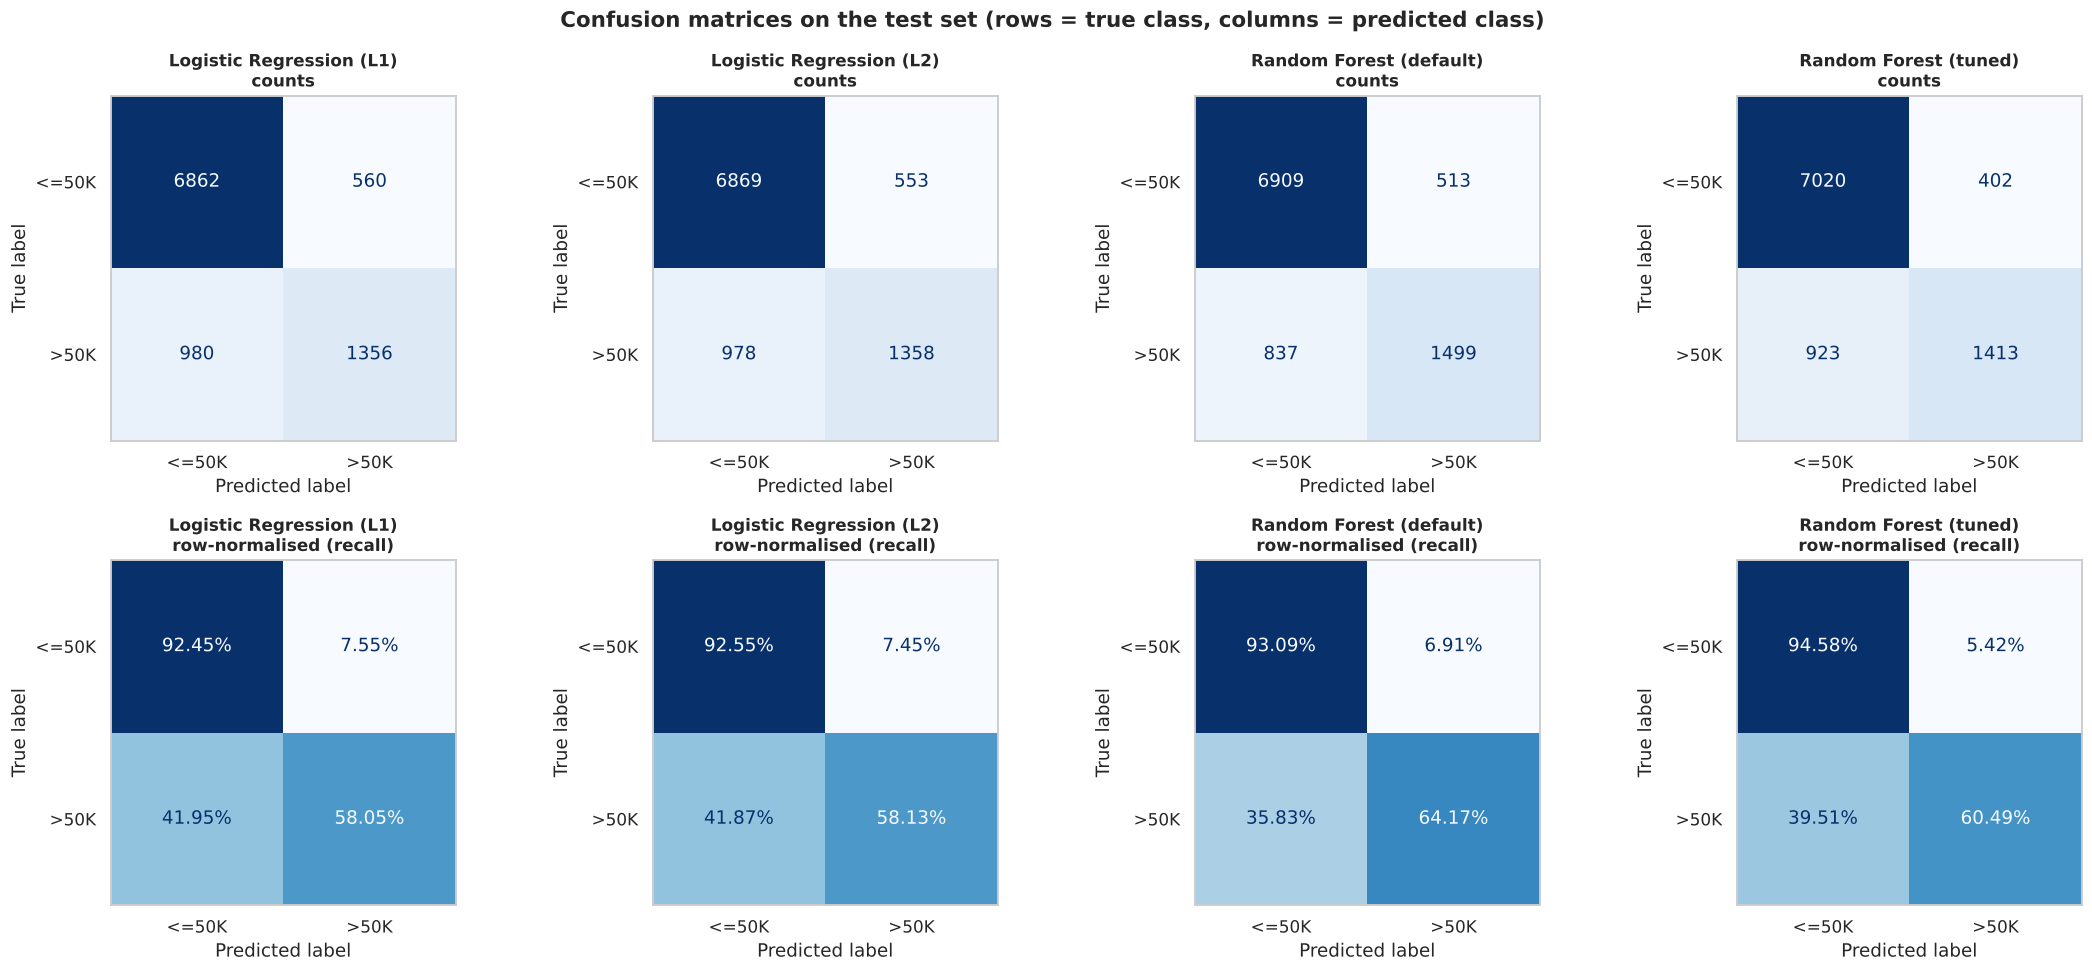

Logistic Regression (L1)   TN=6,862  FP= 560  FN= 980  TP=1,356
Logistic Regression (L2)   TN=6,869  FP= 553  FN= 978  TP=1,358


Random Forest (default)    TN=6,909  FP= 513  FN= 837  TP=1,499
Random Forest (tuned)      TN=7,020  FP= 402  FN= 923  TP=1,413


In [30]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for col, (name, model) in enumerate(models.items()):
    for row, (normalize, fmt, title) in enumerate([(None, "d", "counts"),
                                                   ("true", ".2%", "row-normalised (recall)")]):
        ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=CLASS_NAMES,
                                              normalize=normalize, values_format=fmt,
                                              cmap="Blues", colorbar=False, ax=axes[row, col])
        axes[row, col].set_title(f"{name}\n{title}", fontsize=11)
        axes[row, col].grid(False)
plt.suptitle("Confusion matrices on the test set (rows = true class, columns = predicted class)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

for name, model in models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, model.predict(X_test)).ravel()
    print(f"{name:26s} TN={tn:5,}  FP={fp:4,}  FN={fn:4,}  TP={tp:5,}")

**How to read the confusion matrix**
* **TN** (top-left): `<=50K` correctly predicted · **TP** (bottom-right): `>50K` correctly predicted.
* **FP** (top-right): predicted `>50K` but actually `<=50K` · **FN** (bottom-left): a high earner that the model missed.

**Observations**
* All models recognise the majority class `<=50K` very well (92–95% recall). The **tuned Random Forest makes the fewest false alarms** (402 FP vs ≈ 555 for Logistic Regression), giving the highest precision for `>50K` (0.78) and the highest accuracy (86.4%).
* The difficult part is the minority class `>50K`: at the default 0.5 threshold Logistic Regression finds only ≈ 58% of high earners (≈ 980 missed), the tuned forest ≈ 60% and the default forest ≈ 64%.
* The default forest has a slightly higher recall / F1 for `>50K` than the tuned forest *at threshold 0.5*, but lower accuracy, precision and ROC-AUC. This is not a contradiction: the tuned forest produces better-ranked (better-calibrated) probabilities, but its probabilities for borderline high earners often fall just below 0.5. The threshold analysis in 6.4 shows that, once the threshold is adapted, the tuned forest achieves the best F1 of all models.

### 6.3 ROC and Precision–Recall curves

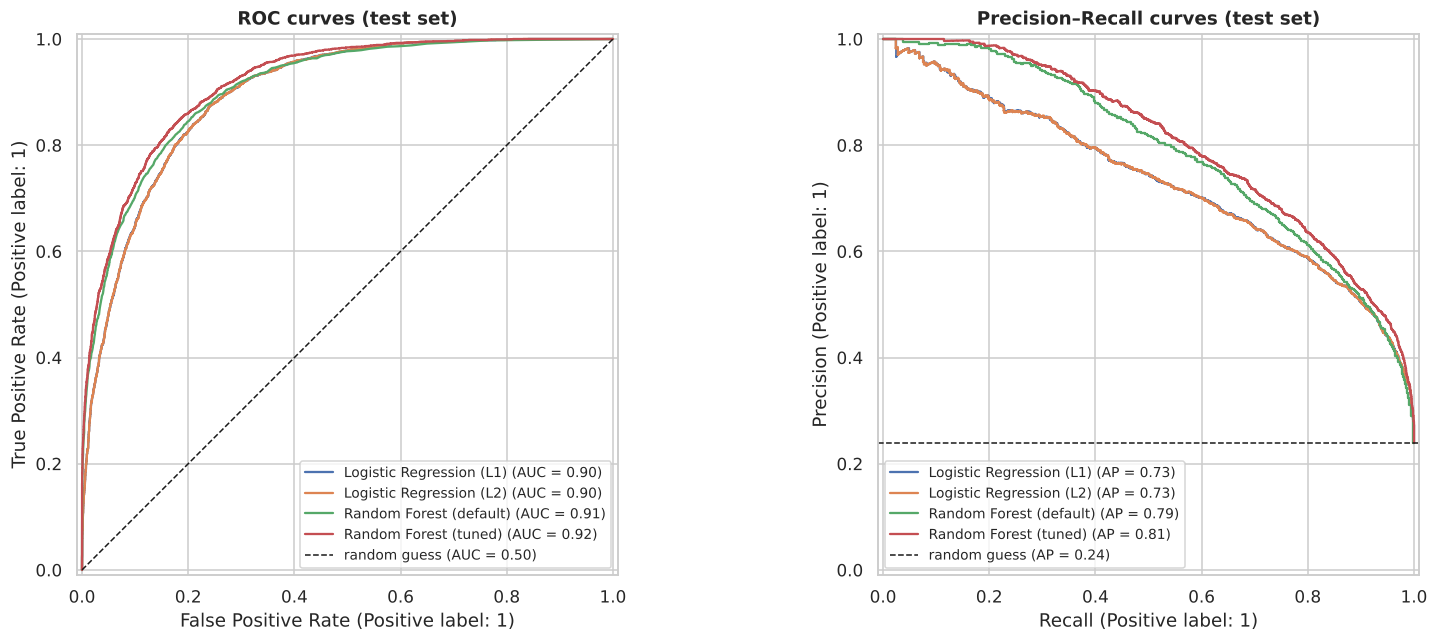

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random guess (AUC = 0.50)")
axes[0].set_title("ROC curves (test set)")
axes[0].legend(loc="lower right", fontsize=9)
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1,
                label=f"random guess (AP = {y_test.mean():.2f})")
axes[1].set_title("Precision–Recall curves (test set)")
axes[1].legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

**Observations**
* All models are far above the random-guess diagonal (ROC-AUC 0.50). The **tuned Random Forest has the highest ROC-AUC (0.918)**, ahead of the default forest (0.908) and Logistic Regression (0.896 for both L1 and L2, whose curves overlap almost perfectly).
* The Precision–Recall curve is more informative for the minority class: the tuned forest's curve lies above the others at almost every recall level (average precision 0.81 vs 0.79 for the default forest and 0.73 for Logistic Regression), i.e. for any desired share of high earners found, it produces fewer false positives. ROC-AUC and PR-AUC do not depend on the 0.5 threshold, which confirms that the tuned forest is the best *ranker*.

### 6.4 Going further: optimising the decision threshold

By default a model predicts `>50K` when the predicted probability is ≥ 0.5. With imbalanced classes this threshold is usually **not** the one that gives the best F1-score for the minority class. We choose, for each model, the threshold that **maximises the F1-score of the `>50K` class**.

To avoid any leakage, the threshold is selected from **out-of-fold predictions on the training set** (`cross_val_predict`), *not* from the test set. The test set is then used only to report the final result.

In [32]:
def best_f1_threshold(model, X_fit, y_fit, cv):
    # Threshold maximising F1 (>50K) on out-of-fold training predictions.
    oof_proba = cross_val_predict(model, X_fit, y_fit, cv=cv, method="predict_proba",
                                  n_jobs=-1)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_fit, oof_proba)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thresholds[np.argmax(f1[:-1])])


final_models = {k: v for k, v in models.items() if k != "Random Forest (default)"}
thresholds = {name: best_f1_threshold(model, X_train, y_train, CV_5 if "Logistic" in name else CV_3)
              for name, model in final_models.items()}
for name, t in thresholds.items():
    print(f"{name:26s} optimal threshold (from training CV) = {t:.3f}")

Logistic Regression (L1)   optimal threshold (from training CV) = 0.310
Logistic Regression (L2)   optimal threshold (from training CV) = 0.319
Random Forest (tuned)      optimal threshold (from training CV) = 0.389


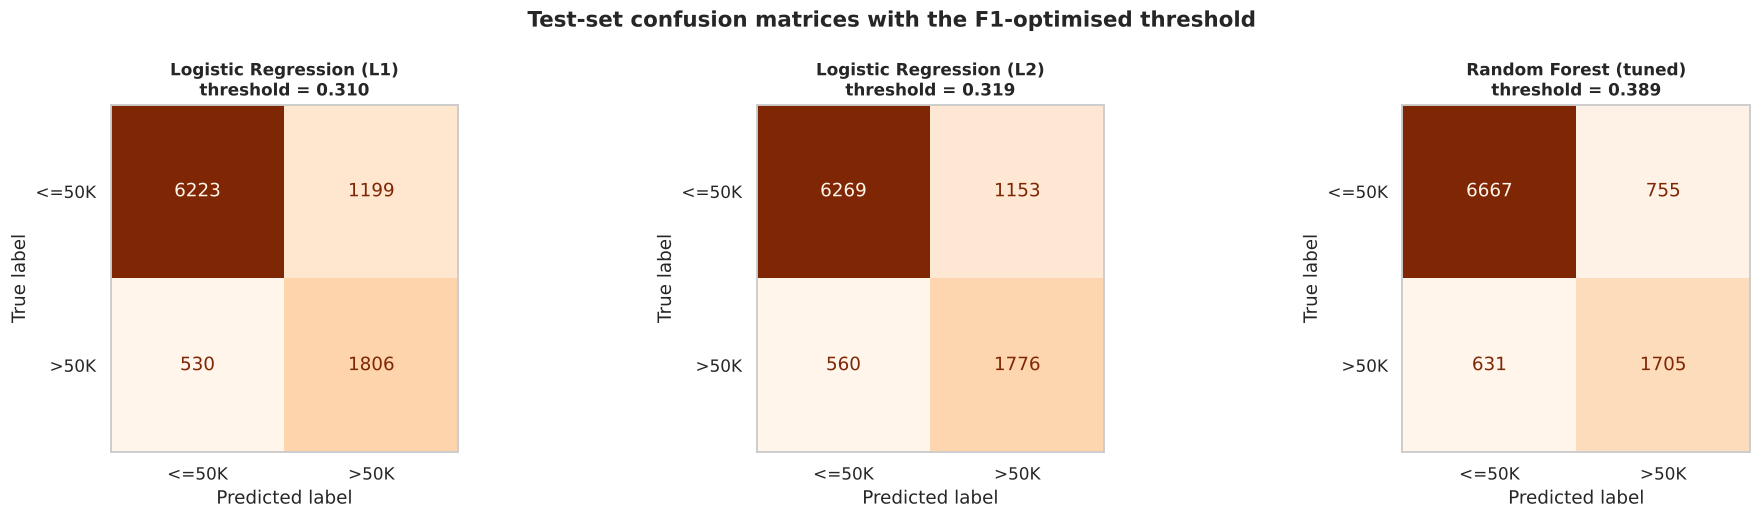

Logistic Regression (L1)  (threshold = 0.310)
              precision    recall  f1-score   support

       <=50K     0.9215    0.8385    0.8780      7422
        >50K     0.6010    0.7731    0.6763      2336

    accuracy                         0.8228      9758
   macro avg     0.7613    0.8058    0.7772      9758
weighted avg     0.8448    0.8228    0.8297      9758

Logistic Regression (L2)  (threshold = 0.319)
              precision    recall  f1-score   support

       <=50K     0.9180    0.8447    0.8798      7422
        >50K     0.6064    0.7603    0.6746      2336

    accuracy                         0.8245      9758
   macro avg     0.7622    0.8025    0.7772      9758
weighted avg     0.8434    0.8245    0.8307      9758



Random Forest (tuned)  (threshold = 0.389)
              precision    recall  f1-score   support

       <=50K     0.9135    0.8983    0.9058      7422
        >50K     0.6931    0.7299    0.7110      2336

    accuracy                         0.8580      9758
   macro avg     0.8033    0.8141    0.8084      9758
weighted avg     0.8608    0.8580    0.8592      9758



In [33]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, (name, model) in zip(axes, final_models.items()):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= thresholds[name]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=CLASS_NAMES, cmap="Oranges",
                                            colorbar=False, ax=ax)
    ax.set_title(f"{name}\nthreshold = {thresholds[name]:.3f}", fontsize=11)
    ax.grid(False)
plt.suptitle("Test-set confusion matrices with the F1-optimised threshold", fontsize=14,
             fontweight="bold")
plt.tight_layout()
plt.show()

for name, model in final_models.items():
    pred = (model.predict_proba(X_test)[:, 1] >= thresholds[name]).astype(int)
    print("=" * 62)
    print(f"{name}  (threshold = {thresholds[name]:.3f})")
    print("=" * 62)
    print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=4))

**Observations**
* The optimal thresholds (≈ 0.31 for Logistic Regression, ≈ 0.39 for the Random Forest) are well below 0.5, which is expected for a minority class: the models need less "evidence" to flag a person as a high earner.
* Lowering the threshold trades some precision for a **large gain in recall** of the `>50K` class (Logistic Regression: 58% → ≈ 77%; tuned Random Forest: 60% → 73%), and the **F1-score of `>50K` increases for every model** (LR: 0.64 → ≈ 0.68; tuned RF: 0.68 → **0.711**, the best value of all). ROC-AUC is unchanged because it does not depend on the threshold.
* The tuned forest keeps a high accuracy (85.8%) at its optimal threshold, while Logistic Regression drops to ≈ 82%, because its probabilities separate the classes less sharply.
* Overall accuracy decreases slightly, because more `<=50K` people are flagged — this is the classic precision/recall trade-off. Which threshold to use in practice depends on the business cost of a false positive versus a false negative.

### 6.5 Final comparison

In [34]:
rows = [evaluate(name, model, X_test, y_test) for name, model in models.items()]
rows += [evaluate(f"{name} + tuned threshold", model, X_test, y_test, thresholds[name])
         for name, model in final_models.items()]
results = pd.DataFrame(rows).set_index("model")

majority_baseline = 1 - y_test.mean()
print(f"Majority-class baseline accuracy (always predict '<=50K'): {majority_baseline:.4f}\n")
metric_cols = [c for c in results.columns if c != "threshold"]
(results.style.format("{:.4f}")
        .format({"threshold": "{:.3f}"})
        .highlight_max(subset=metric_cols, color="#C6EFCE")
        .set_caption("Test-set performance (best value per metric highlighted)"))

Majority-class baseline accuracy (always predict '<=50K'): 0.7606



,threshold,accuracy,precision (>50K),recall (>50K),F1 (>50K),F1 (macro),ROC-AUC,PR-AUC
model,,,,,,,,
Logistic Regression (L1),0.500,0.842181,0.707724,0.580479,0.637817,0.768463,0.896156,0.733651
Logistic Regression (L2),0.500,0.843103,0.710623,0.581336,0.639510,0.769621,0.896122,0.733506
Random Forest (default),0.500,0.861345,0.742477,0.644264,0.689892,0.800302,0.908346,0.787759
Random Forest (tuned),0.500,0.864214,0.778512,0.604880,0.680800,0.797282,0.917580,0.805243
Logistic Regression (L1) + tuned threshold,0.310,0.822812,0.600998,0.773116,0.676278,0.777151,0.896156,0.733651
Logistic Regression (L2) + tuned threshold,0.319,0.824452,0.606350,0.760274,0.674644,0.777221,0.896122,0.733506
Random Forest (tuned) + tuned threshold,0.389,0.857963,0.693089,0.729880,0.711009,0.808426,0.917580,0.805243


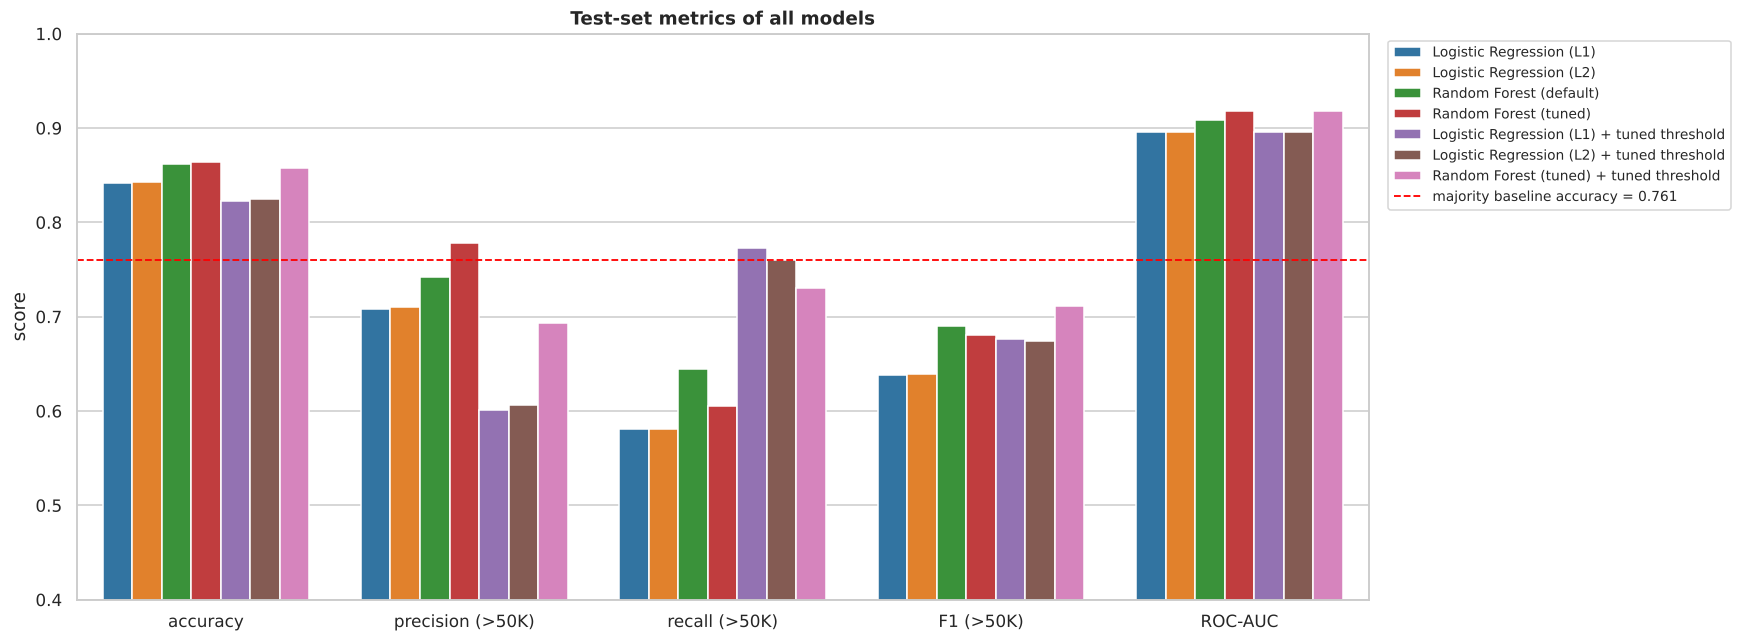

In [35]:
plot_metrics = ["accuracy", "precision (>50K)", "recall (>50K)", "F1 (>50K)", "ROC-AUC"]
plot_df = results[plot_metrics].reset_index().melt(id_vars="model", var_name="metric",
                                                   value_name="score")

fig, ax = plt.subplots(figsize=(16, 6))
sns.barplot(data=plot_df, x="metric", y="score", hue="model", palette="tab10", ax=ax)
ax.axhline(majority_baseline, color="red", ls="--", lw=1.2,
           label=f"majority baseline accuracy = {majority_baseline:.3f}")
ax.set(ylim=(0.4, 1.0), title="Test-set metrics of all models", xlabel="", ylabel="score")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

In [36]:
overfit = pd.DataFrame({
    "train accuracy": [accuracy_score(y_train, m.predict(X_train)) for m in models.values()],
    "test accuracy": [accuracy_score(y_test, m.predict(X_test)) for m in models.values()],
}, index=list(models))
overfit["gap"] = overfit["train accuracy"] - overfit["test accuracy"]
overfit.style.format("{:.4f}").set_caption("Over-fitting check (threshold 0.5)")

,train accuracy,test accuracy,gap
Logistic Regression (L1),0.8477,0.8422,0.0055
Logistic Regression (L2),0.8476,0.8431,0.0045
Random Forest (default),0.9999,0.8617,0.1383
Random Forest (tuned),0.8960,0.8642,0.0318


### 6.6 Which features really matter? Permutation importance on the test set

Permutation importance measures how much the test-set ROC-AUC of the final Random Forest **drops when one column is randomly shuffled** (which destroys its relationship with the target). Unlike Gini importance it is measured on unseen data and is not biased towards high-cardinality features. It is purely an interpretation step — no modelling decision is based on it.

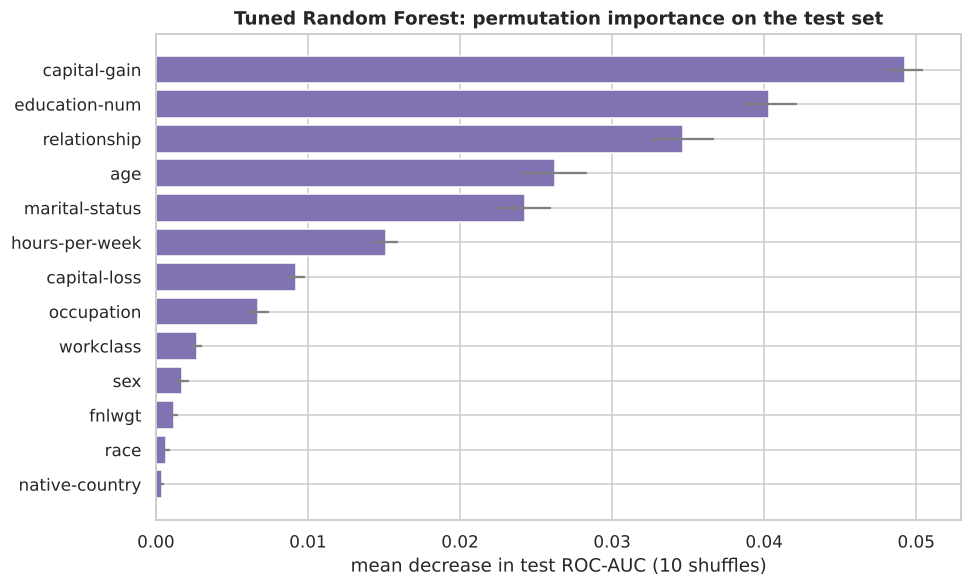

In [37]:
perm = permutation_importance(random_forest, X_test, y_test, scoring="roc_auc", n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
perm_std = pd.Series(perm.importances_std, index=X_test.columns)[perm_imp.index]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(perm_imp.index, perm_imp, xerr=perm_std, color="#8172B2", ecolor="gray")
ax.set(title="Tuned Random Forest: permutation importance on the test set",
       xlabel="mean decrease in test ROC-AUC (10 shuffles)")
plt.tight_layout()
plt.show()

**Observations**
* On unseen data the most useful features are **`capital-gain`, `education-num`, `relationship`, `age` and `marital-status`**, followed by `hours-per-week` — the same top group as the Gini importance, which makes the interpretation robust.
* **`fnlwgt` drops from 7th place (Gini) to almost zero (≈ 0.001 AUC)**: shuffling it does not hurt the model. This confirms that its Gini importance was an artefact of the bias towards continuous features, and that it carries no real information about income (as already suggested by the EDA).
* `sex`, `race` and `native-country` have very small permutation importance: once education, occupation, marital status, etc. are known, they add little to the prediction.

---
## Conclusions

### Answers to the assignment tasks
1. **EDA (①):** the dataset has 48,842 records, 3 columns with missing values (`?` → handled as an `"Unknown"` category), 52 duplicates, a redundant `education` column and an imbalanced target (≈ 76% `<=50K` / 24% `>50K`). The strongest predictors are marital status / relationship, education, capital gain, age, occupation and working hours.
2. **Target encoding (②):** `<=50K` → 0 and `>50K` → 1.
3. **Train/test split (③):** stratified 80% / 20% split with identical class proportions in both sets.
4. **Logistic Regression with L1 and L2 (④):** both penalties, with `C` tuned by 5-fold CV (best `C` = 1 for L1, ≈ 0.32 for L2), reach **84.3% test accuracy and ROC-AUC ≈ 0.896**, with almost no over-fitting (train/test gap < 1 point). L1 produces a sparser model (10 of 75 coefficients set to 0) with the same performance.
5. **Random Forest (⑤):** the tuned forest (`max_depth=16`, `min_samples_leaf=2`, `max_features="sqrt"`) is the **best model**: **86.4% test accuracy, ROC-AUC 0.918, PR-AUC 0.805** and the highest precision for `>50K` (0.78). Tuning reduced the over-fitting of the default forest (train/test gap 13.8 → 3.2 points).
6. **Evaluation (⑥):** confusion matrices and classification reports show that all models identify `<=50K` very well (92–95% recall); the main difficulty is the minority `>50K` class. Optimising the decision threshold on training CV predictions raises the F1-score of `>50K` for every model — the **tuned Random Forest with threshold 0.39 reaches the best F1 (0.711) and macro-F1 (0.808)** while keeping 85.8% accuracy.

| Final model (test set) | Accuracy | Precision >50K | Recall >50K | F1 >50K | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression (L1) | 0.842 | 0.708 | 0.580 | 0.638 | 0.896 |
| Logistic Regression (L2) | 0.843 | 0.711 | 0.581 | 0.640 | 0.896 |
| Random Forest (tuned) | **0.864** | **0.779** | 0.605 | 0.681 | **0.918** |
| Random Forest (tuned) + threshold 0.39 | 0.858 | 0.693 | **0.730** | **0.711** | **0.918** |

### Model comparison
| Aspect | Logistic Regression (L1 / L2) | Random Forest (tuned) |
|---|---|---|
| Test performance | Good (accuracy 84.3%, ROC-AUC 0.896) | **Best** (accuracy 86.4%, ROC-AUC 0.918) |
| Non-linearities & interactions | Not captured (linear decision boundary) | Captured automatically |
| Interpretability | **High** — coefficients = effect on log-odds; L1 selects features | Medium — feature importances only |
| Preprocessing needs | Scaling, encoding, log-transform | Minimal |
| Training cost | **Very low** | Higher (hundreds of trees) |

**Recommendation:** use the **tuned Random Forest** when predictive performance matters most (optionally with the F1-optimised threshold if finding high earners is the priority); use **L1 Logistic Regression** when a simple, transparent and explainable model is required — it loses only about 2 percentage points of accuracy.

### Limitations and possible improvements
* Gradient-boosting models (e.g. `HistGradientBoostingClassifier`, XGBoost, LightGBM) usually gain a further ~1 point of accuracy on this dataset.
* The data come from the 1994 US census; income patterns have changed since then, so the models should not be applied to today's population without retraining.
* Sensitive attributes (`sex`, `race`, `native-country`) influence the predictions; a real-world deployment would require a fairness assessment.